<a href="https://colab.research.google.com/github/aayushcs007/BIS_LAB-1BF24CS007-/blob/main/genetic_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Generation   1 | x = -1.18059288 | y = -0.92163628 | Fitness = 9.2070237684
Generation   2 | x = -0.95387460 | y =  0.02618705 | Fitness = 1.4626521173
Generation   3 | x = -0.95387460 | y =  0.02618705 | Fitness = 1.4626521173
Generation   4 | x =  0.00513810 | y = -0.08018687 | Fitness = 1.2542626592
Generation   5 | x =  0.00513810 | y = -0.08018687 | Fitness = 1.2542626592
Generation   6 | x =  0.00513810 | y = -0.08018687 | Fitness = 1.2542626592
Generation   7 | x =  0.00513810 | y = -0.08018687 | Fitness = 1.2542626592
Generation   8 | x = -0.03838036 | y = -0.03785443 | Fitness = 0.5737921364
Generation   9 | x = -0.03838036 | y = -0.03785443 | Fitness = 0.5737921364
Generation  10 | x =  0.01033889 | y =  0.02181316 | Fitness = 0.1154500589
Generation  11 | x =  0.01037739 | y =  0.02173414 | Fitness = 0.1149275887
Generation  12 | x =  0.01955843 | y =  0.00946406 | Fitness = 0.0935608239
Generation  13 | x =  0.01955843 | y =  0.00946406 | Fitness = 0.0935608239
Generation  

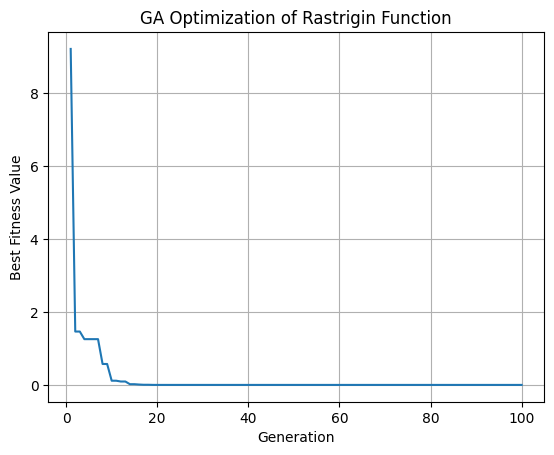

In [1]:

import random
import math
import matplotlib.pyplot as plt

# Rastrigin Function
def rastrigin(individual):
    return 20 + sum(
        x**2 - 10 * math.cos(2 * math.pi * x)
        for x in individual
    )

# Parameters
POPULATION_SIZE = 50
GENERATIONS = 100
DIMENSIONS = 2
LOWER_BOUND = -5.12
UPPER_BOUND = 5.12
MUTATION_RATE = 0.05
CROSSOVER_RATE = 0.8

# Generate initial population
population = [
    [random.uniform(LOWER_BOUND, UPPER_BOUND)
     for _ in range(DIMENSIONS)]
    for _ in range(POPULATION_SIZE)
]

best_fitness_history = []

# Genetic Algorithm
for generation in range(GENERATIONS):

    # Evaluate fitness
    population.sort(key=rastrigin)

    # Best individual of current generation
    best = population[0]
    best_fitness = rastrigin(best)

    best_fitness_history.append(best_fitness)

    print(
        f"Generation {generation + 1:3d} | "
        f"x = {best[0]: .8f} | "
        f"y = {best[1]: .8f} | "
        f"Fitness = {best_fitness:.10f}"
    )

    # Elitism: preserve best individual
    new_population = [best.copy()]

    # Selection, crossover and mutation
    while len(new_population) < POPULATION_SIZE:

        # Select parents from better half
        parent1 = random.choice(population[:POPULATION_SIZE // 2])
        parent2 = random.choice(population[:POPULATION_SIZE // 2])

        # Arithmetic crossover
        if random.random() < CROSSOVER_RATE:
            alpha = random.random()

            child = [
                alpha * parent1[i] + (1 - alpha) * parent2[i]
                for i in range(DIMENSIONS)
            ]
        else:
            child = parent1.copy()

        # Gaussian mutation
        for i in range(DIMENSIONS):
            if random.random() < MUTATION_RATE:
                child[i] += random.gauss(0, 0.2)

                child[i] = max(
                    LOWER_BOUND,
                    min(UPPER_BOUND, child[i])
                )

        new_population.append(child)

    population = new_population

# Final result
population.sort(key=rastrigin)

best_solution = population[0]
best_value = rastrigin(best_solution)

print("\n========== FINAL RESULT ==========")
print(f"Best x = {best_solution[0]}")
print(f"Best y = {best_solution[1]}")
print(f"Minimum Function Value = {best_value}")
print("Theoretical Global Optimum = 0 at (0, 0)")

# Convergence graph
plt.plot(range(1, GENERATIONS + 1), best_fitness_history)
plt.xlabel("Generation")
plt.ylabel("Best Fitness Value")
plt.title("GA Optimization of Rastrigin Function")
plt.grid(True)
plt.show()
